# **DATA ANALYSIS PYTHON PROJECT-"DIWALI SALES ANALYSIS"**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**LOAD & INSPECT THE DATASET**

In [3]:
df = pd.read_csv(
    "Diwali Sales Data.csv",
    encoding="latin1"
)

In [42]:
df.head(2)

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN


In [4]:
df.shape

(11251, 15)

In [5]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount', 'Status', 'unnamed1'],
      dtype='str')

**CHECK DATA QUALITY & CLEANING**

In [6]:
df.isna().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

In [45]:
df=df.drop(columns=["Status","unnamed1"])

In [8]:
df["Amount"]=df["Amount"].fillna(df["Amount"].median())

In [9]:
df.isna().sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

**Data Cleaning — Duplicate Records
Checked the dataset for duplicate rows, identified 8 duplicate records, removed them, and verified that no duplicates remained.**

In [44]:
df.duplicated().sum()

np.int64(8)

In [7]:
df[df.duplicated()]

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
19,1001883,Praneet,P00029842,M,51-55,54,1,Uttar Pradesh,Central,Hospitality,Auto,1,23568.0,NaN,NaN
4404,1004725,Jackson,P00150842,F,36-45,37,1,Maharashtra,Western,Hospitality,Electronics & Gadgets,4,9859.0,NaN,NaN
5703,1003208,Bowman,P00171642,F,26-35,31,0,Bihar,Eastern,Agriculture,Electronics & Gadgets,4,8088.0,NaN,NaN
5908,1001260,Dheeraj,P00344042,M,26-35,28,0,Maharashtra,Western,IT Sector,Electronics & Gadgets,4,8015.0,NaN,NaN
6173,1001325,Reese,P00111742,F,26-35,27,1,Gujarat,Western,Construction,Electronics & Gadgets,3,7923.0,NaN,NaN
8651,1000083,Gute,P00242842,M,26-35,35,0,Uttar Pradesh,Central,Hospitality,Clothing & Apparel,3,5345.0,NaN,NaN
8941,1001476,Anudeep,P00036842,M,18-25,25,0,Maharashtra,Western,IT Sector,Clothing & Apparel,4,5202.0,NaN,NaN
10571,1004404,Rittenbach,P00150142,F,26-35,28,1,Haryana,Northern,Aviation,Electronics & Gadgets,3,2304.0,NaN,NaN


In [14]:
df=df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

**Check Data types**

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 11243 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11243 non-null  int64  
 1   Cust_name         11243 non-null  str    
 2   Product_ID        11243 non-null  str    
 3   Gender            11243 non-null  str    
 4   Age Group         11243 non-null  str    
 5   Age               11243 non-null  int64  
 6   Marital_Status    11243 non-null  int64  
 7   State             11243 non-null  str    
 8   Zone              11243 non-null  str    
 9   Occupation        11243 non-null  str    
 10  Product_Category  11243 non-null  str    
 11  Orders            11243 non-null  int64  
 12  Amount            11243 non-null  float64
dtypes: float64(1), int64(4), str(8)
memory usage: 1.2 MB


### Business Problem 1: Understand the customer and gender distribution



In [17]:
Gender_count = df["Gender"].value_counts()

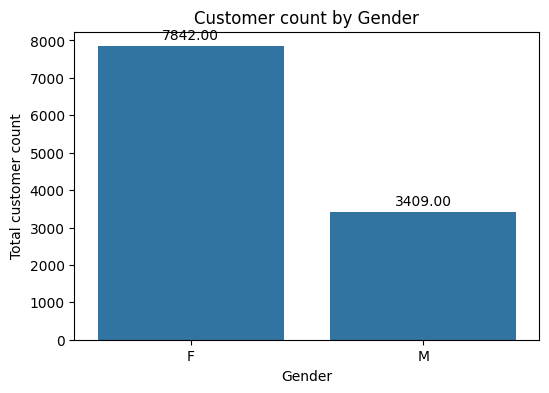

In [8]:
plt.figure(figsize=(6,4))
ax=sns.countplot(data=df,x="Gender")
for container in ax.containers:
    ax.bar_label(container,fmt="%.2f",padding=3)
plt.title("Customer count by Gender")
plt.xlabel("Gender")
plt.ylabel("Total customer count")
plt.show()

### BUSINESS INSIGHT-

The Analysis shows that the female customers have a higher count than male customers with 7,838 female customers compared with 3,405 male customers.

### Business Problem 2: Understand customer age profile.

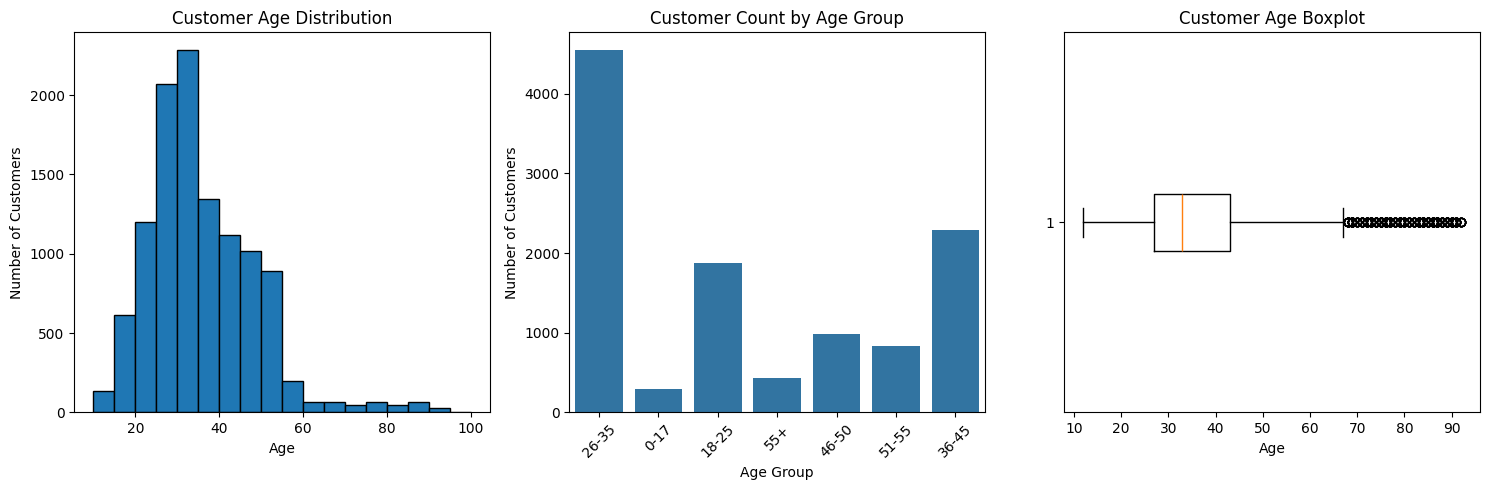

In [9]:
plt.figure(figsize=(15, 5))

# 1. Age Distribution
plt.subplot(1, 3, 1)
plt.hist(df["Age"], bins=range(10, 101, 5), edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

# 2. Age Group Distribution
plt.subplot(1, 3, 2)
sns.countplot(data=df, x="Age Group")
plt.title("Customer Count by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

# 3. Age Boxplot
plt.subplot(1, 3, 3)
plt.boxplot(df["Age"], vert=False)
plt.title("Customer Age Boxplot")
plt.xlabel("Age")

plt.tight_layout()
plt.show()

 ### BUSINESS INSIGHT- 
 
 The customer base is primarily made up of young and middle-aged customers, with the 26–35 age group representing the largest customer segment. Customer concentration is strongest around the late 20s to mid-30s, while older customers form a relatively smaller portion of the dataset. The boxplot also identifies several potential high-age outliers that may require further investigation.

### BUSINESS PROBLEM 3: Analyze purchase contribution by Age Group

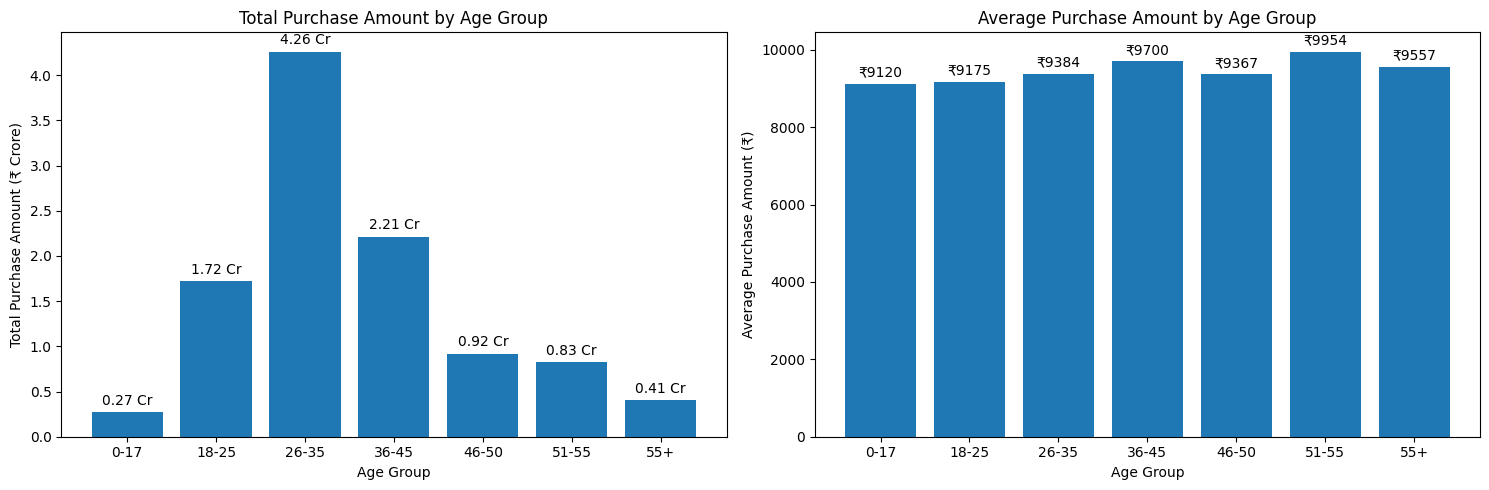

In [10]:
# Calculate total and average purchase amount by age group

age_group_analysis = df.groupby("Age Group")["Amount"].agg(["sum", "mean"])

# Arrange age groups in logical order
age_order = ["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"]

age_group_analysis = age_group_analysis.reindex(age_order)

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Total Purchase Amount
bars1 = axes[0].bar(
    age_group_analysis.index,
    age_group_analysis["sum"] / 1e7
)
axes[0].set_title("Total Purchase Amount by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Total Purchase Amount (₹ Crore)")
axes[0].bar_label(bars1, fmt="%.2f Cr", padding=3)

# 2. Average Purchase Amount
bars2 = axes[1].bar(
    age_group_analysis.index,
    age_group_analysis["mean"]
)
axes[1].set_title("Average Purchase Amount by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Average Purchase Amount (₹)")
axes[1].bar_label(bars2, fmt="₹%.0f", padding=3)

plt.tight_layout()
plt.show()

### BUSINESS INSIGHT-

The 26–35 age group contributes the highest total purchase amount at approximately ₹4.26 Cr. However, the average purchase amount across age groups is relatively similar, ranging from approximately ₹9,120 to ₹9,954.

### BUSINESS PROBLEM 4: Analyze Customer Segment Purchase Behavior

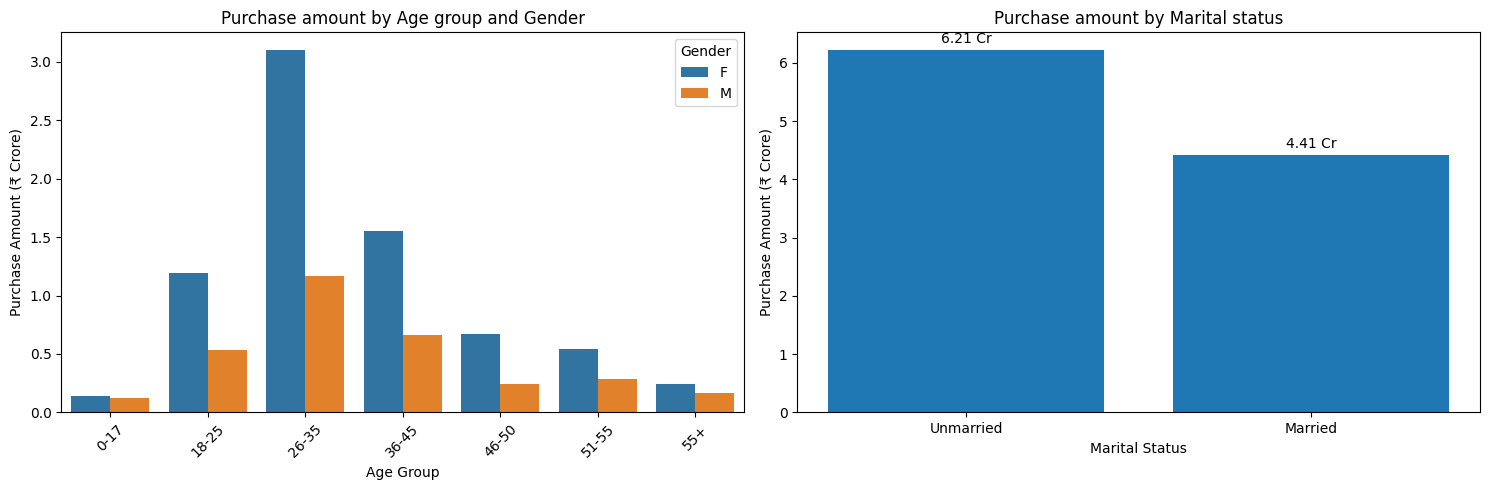

In [11]:
age_gender=df.groupby(["Age Group","Gender"])["Amount"].sum().reset_index()
marital_status=df.groupby("Marital_Status")["Amount"].sum()

fig,axes=plt.subplots(1,2,figsize=(15,5))
age_gender["Amount_Cr"] = age_gender["Amount"] / 1e7

sns.barplot(data=age_gender,x="Age Group",y="Amount_Cr", hue="Gender",ax=axes[0])
axes[0].set_title("Purchase amount by Age group and Gender")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Purchase Amount (₹ Crore)")
axes[0].tick_params(axis="x",rotation=45)

marital_cr = marital_status / 1e7
bars=axes[1].bar(["Unmarried","Married"],marital_cr)
axes[1].set_title("Purchase amount by Marital status")
axes[1].set_xlabel("Marital Status")
axes[1].set_ylabel("Purchase Amount (₹ Crore)")
axes[1].bar_label(bars, fmt="%.2f Cr", padding=3)

plt.tight_layout()
plt.show()

### BUSINES INSIGHT-

Female customers contribute a higher total purchase amount than male customers across all age groups, with the 26–35 female segment contributing the highest amount at approximately ₹3.10 Cr. In terms of marital status, unmarried customers contribute approximately ₹6.21 Cr, compared with approximately ₹4.41 Cr from married customers.

### BUSINESS PROBLEM 5: Identify the strongest geographic markets

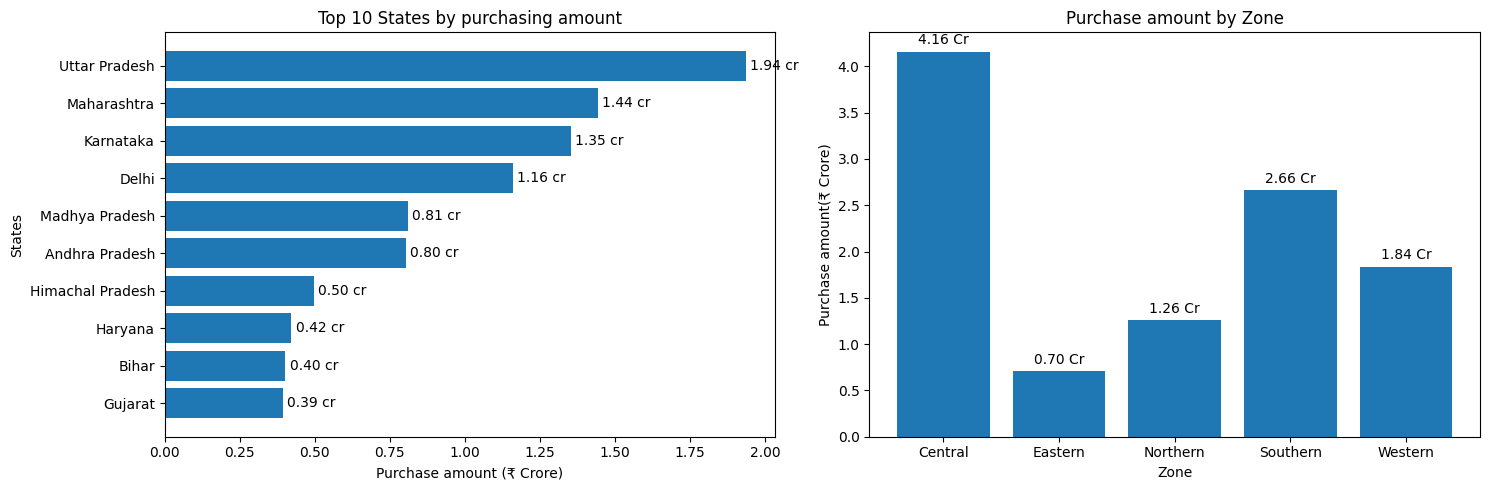

In [12]:
state_amount = df.groupby("State")["Amount"].sum()
Top_10_states = state_amount.nlargest(10)
Top_10_states_cr = Top_10_states / 1e7
zone_amount = df.groupby("Zone")["Amount"].sum()
zone_cr = zone_amount / 1e7

fig,axes = plt.subplots(1,2,figsize=(15,5))

bars1 = axes[0].barh(Top_10_states_cr.index,Top_10_states_cr.values)
axes[0].set_title("Top 10 States by purchasing amount")
axes[0].set_xlabel("Purchase amount (₹ Crore)")
axes[0].set_ylabel("States")
axes[0].invert_yaxis()
axes[0].bar_label(bars1,fmt="%.2f cr",padding=3)

bars2 = axes[1].bar(zone_cr.index,zone_cr.values)
axes[1].set_title("Purchase amount by Zone")
axes[1].set_xlabel("Zone")
axes[1].set_ylabel("Purchase amount(₹ Crore)")
axes[1].bar_label(bars2,fmt="%.2f Cr",padding=3)

plt.tight_layout()
plt.show()

### BUSINESS INSIGHT-

Uttar Pradesh contributes the highest total purchase amount among the states, at approximately ₹1.94 Cr. Among the zones, the Central Zone contributes the highest purchase amount, at approximately ₹4.16 Cr.

### BUSINESS PROBLEM 6: Analyze customer occupation and its purchase contribution.

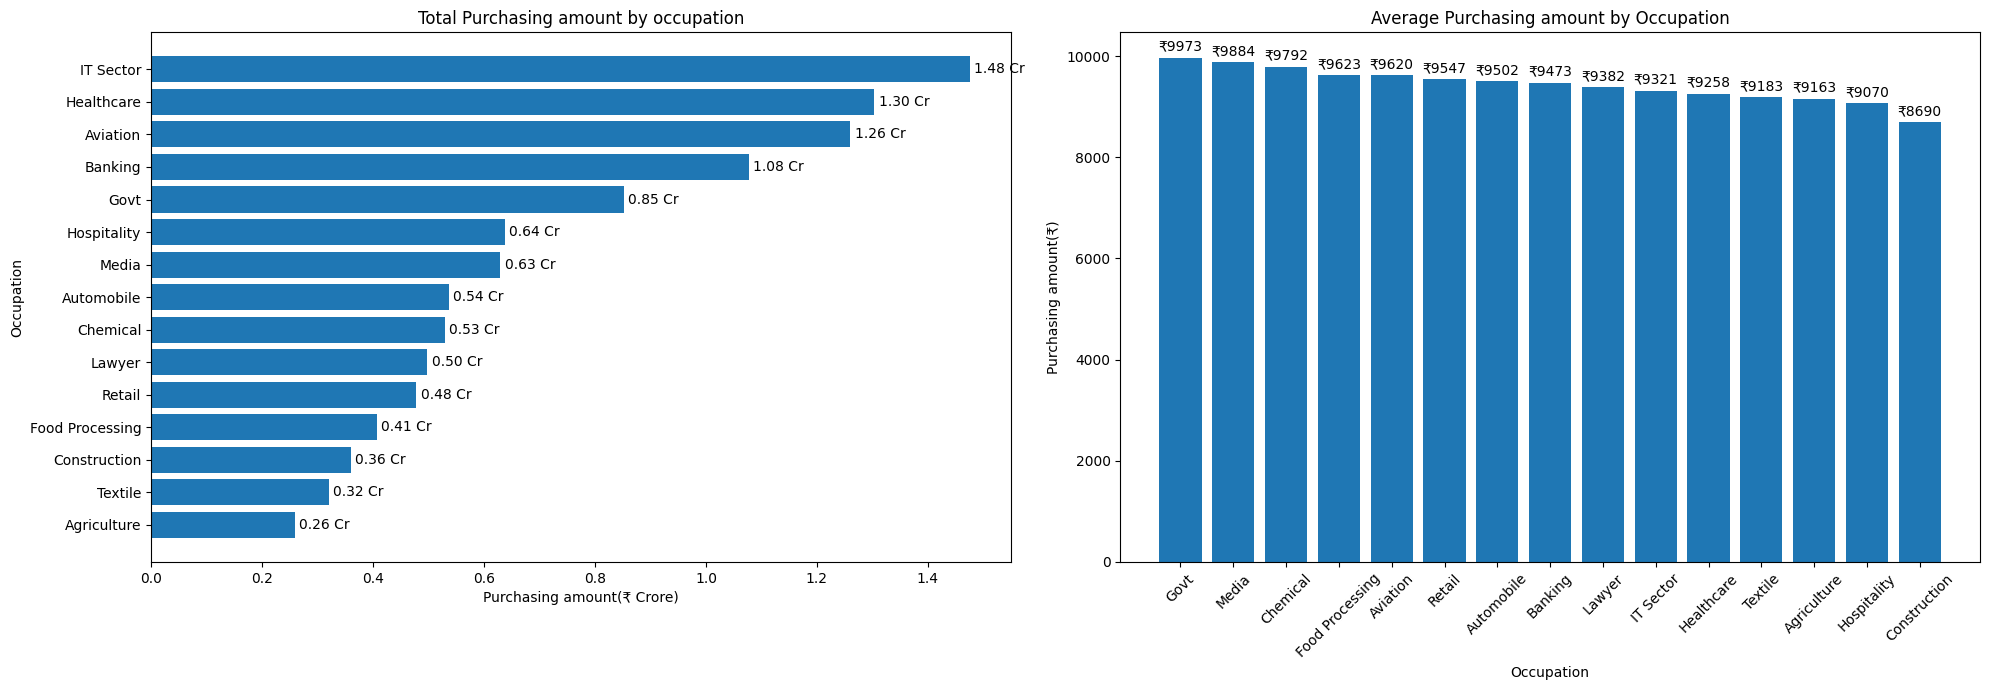

In [13]:
occupation_total = df.groupby("Occupation")["Amount"].sum().sort_values(ascending=False)
occupation_total_cr = occupation_total / 1e7

fig, axes = plt.subplots(1,2,figsize=(20,7))

bars1 = axes[0].barh(occupation_total_cr.index,occupation_total_cr.values)
axes[0].set_title("Total Purchasing amount by occupation")
axes[0].set_xlabel("Purchasing amount(₹ Crore)")
axes[0].set_ylabel("Occupation")
axes[0].invert_yaxis()
axes[0].bar_label(bars1,fmt="%.2f Cr",padding=3)

occupation_average = df.groupby("Occupation")["Amount"].mean().sort_values(ascending=False)
bars2 = axes[1].bar(occupation_average.index,occupation_average.values)
axes[1].set_title("Average Purchasing amount by Occupation")
axes[1].set_xlabel("Occupation")
axes[1].set_ylabel("Purchasing amount(₹)")
axes[1].tick_params(axis="x",rotation=45)
axes[1].bar_label(bars2,fmt="₹%.0f",padding=3)

plt.tight_layout()
plt.show()

### BUSINESS INSIGHT-

IT Sector customers contribute the highest total purchase amount at approximately ₹1.48 Cr, followed by Healthcare at ₹1.30 Cr and Aviation at ₹1.26 Cr. However, average purchase amounts across occupations are relatively close, ranging from approximately ₹8,691 to ₹9,973 per purchase.

### BUSINESS PROBLEM 7: Analyze Product Category Performance

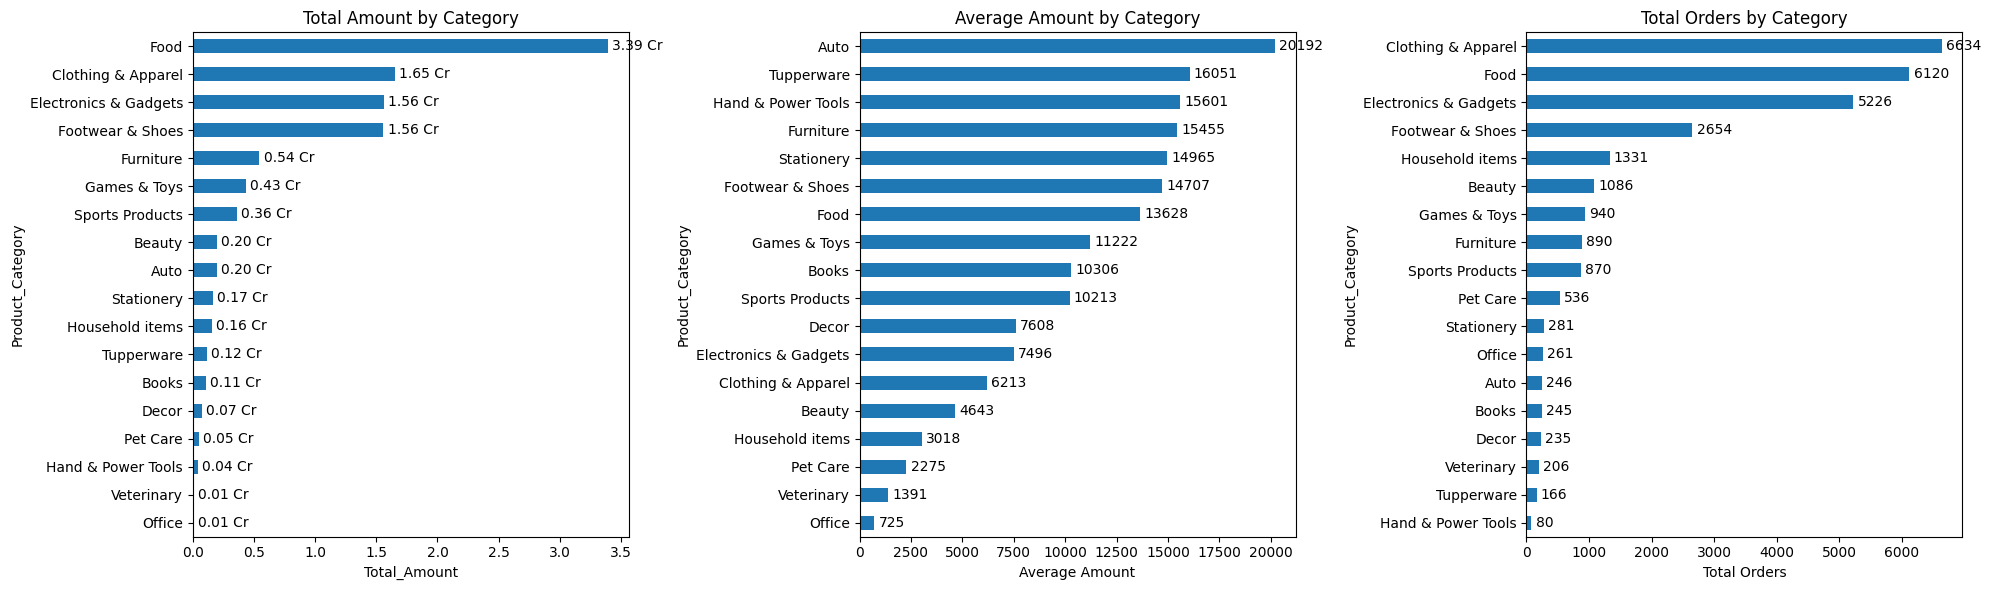

In [14]:
category_analysis = df.groupby("Product_Category").agg(
    Total_Amount=("Amount", "sum"),
    Average_Amount=("Amount", "mean"),
    Total_Orders=("Orders", "sum"))
fig,axes = plt.subplots(1,3,figsize=(20,6))
category_analysis["Total_Amount_Cr"] = (
    category_analysis["Total_Amount"] / 1e7)
category_analysis["Total_Amount_Cr"].sort_values().plot(kind="barh",ax=axes[0])

axes[0].set_title("Total Amount by Category")
axes[0].set_xlabel("Total_Amount")
axes[0].set_ylabel("Product_Category")
for container in axes[0].containers:
    axes[0].bar_label(container,fmt="%.2f Cr",padding=3)
category_analysis["Average_Amount"].sort_values().plot(kind="barh",ax=axes[1])

axes[1].set_title("Average Amount by Category")
axes[1].set_xlabel("Average Amount")
axes[1].set_ylabel("Product_Category")
for container in axes[1].containers:
    axes[1].bar_label(container,fmt="%.0f",padding=3)
category_analysis["Total_Orders"].sort_values().plot(kind="barh",ax=axes[2])

axes[2].set_title("Total Orders by Category")
axes[2].set_xlabel("Total Orders")
axes[2].set_ylabel("Product_Category")
for container in axes[2].containers:
    axes[2].bar_label(container,fmt="%.0f",padding=3)
    
plt.tight_layout()
plt.show()

### BUSINESS INSIGHT-

Food generates the highest total sales (~₹3.40 Cr), supported by a high order volume (~6,120), while Clothing & Apparel has the highest order volume (~6,627) but lower total sales. Auto has the highest average purchase value, indicating that some categories generate value through higher-value purchases rather than order volume.

### BUSINESS PROBLEM 8: Analyze purchase behavior distribution and identify potential high-value purchases/customers

In [21]:
df["Amount"].describe()

count    11239.000000
mean      9453.610858
std       5222.355869
min        188.000000
25%       5443.000000
50%       8109.000000
75%      12675.000000
max      23952.000000
Name: Amount, dtype: float64

In [22]:
high_value_threshold = df["Amount"].quantile(0.75)
high_value_threshold

np.float64(12675.0)

In [23]:
len(df[df["Amount"] >= high_value_threshold]) / len(df) * 100

24.975557728201938

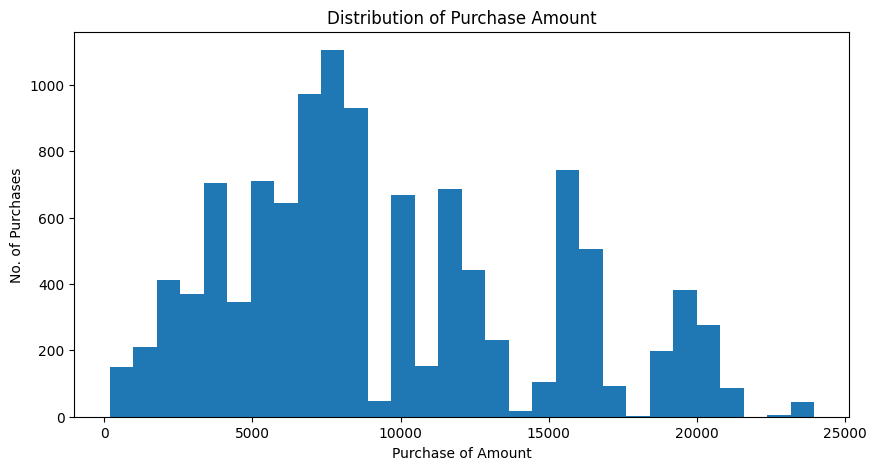

In [24]:
plt.figure(figsize=(10,5))
plt.hist(df["Amount"],bins=30)
plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase of Amount")
plt.ylabel("No. of Purchases")
plt.show()

In [25]:
high_value_purchase = df[df["Amount"] >= high_value_threshold]
high_value_by_age = high_value_purchase.groupby("Age Group")["Amount"].agg(["sum","mean","count"]).sort_values("sum",ascending=False)
high_value_by_age
    

,sum,mean,count
Age Group,,,
26-35,19223021.94,16966.480088,1133
36-45,10470163.49,16942.012120,618
18-25,7386337.00,16980.085057,435
51-55,3902234.00,17190.458150,227
46-50,3868406.00,17116.840708,226
55+,1819808.00,17007.551402,107
0-17,1074296.00,16785.875000,64


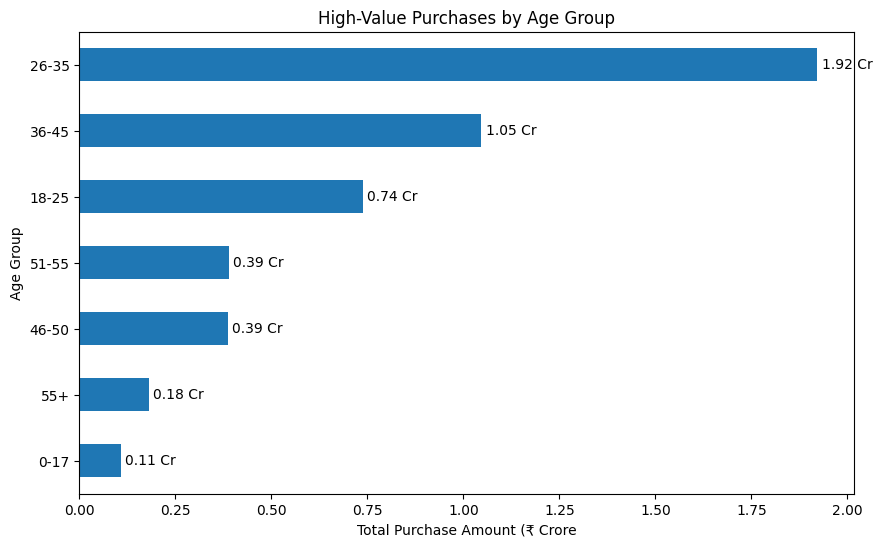

In [26]:
plt.figure(figsize=(10,6))
ax = (high_value_by_age["sum"]/10000000).sort_values().plot(kind="barh")
plt.title("High-Value Purchases by Age Group")
plt.xlabel("Total Purchase Amount (₹ Crore")
plt.ylabel("Age Group")
for container in ax.containers:
    ax.bar_label(container,fmt="%.2f Cr",padding=3)
plt.show()

In [ ]:
high_value_customers = (high_value_purchase.groupby("User_ID")["Amount"].agg(["sum", "count", "mean"]).sort_values("sum", ascending=False))
high_value_customers.head(10)

### BUSINESS INSIGHT-

The top high-value customer made 10 high-value purchases totaling ₹1.79 lakh, while the next highest customer made 7 purchases totaling ₹1.37 lakh. This indicates a small group of customers contributes substantial high-value purchase activity and could be considered potential high-value customers.

### **KEY BUSINESS FINDINGS**

**1)Customer Performance:** The 26–35 age group represents the strongest purchasing segment, with female customers contributing a larger share of total purchases.

**2)Product Performance:** from the Analysis Food generates the highest total sales, while Clothing & Apparel leads in order volume and Auto records the highest average purchase value.

**3)Geographic Sales record:** Uttar Pradesh, Maharashtra, Karnataka and Delhi are among the leading states by total purchase amount.

**4)High-Value Purchasing distribution:** Comparably a small group of customers shows repeated high-value purchasing behavior, creating an opportunity for targeted retention and Purchases above ₹12,672 represent the top 25% of transactions provide a useful basis for identifying potential high-value customers.

### **BUSINESS RECOMMENDATIONS**

**1. Target the 26–35 segment**
Develop personalized campaigns and product recommendations for the strongest purchasing age group.

**2. Strengthen high-performing markets**
Prioritize inventory, promotions and customer engagement in states generating higher purchase values.

**3. Use category-specific strategies**
Support high-volume categories such as Clothing & Apparel and high-revenue categories such as Food, while using premium strategies for high-average-value categories such as Auto.

**4. Build a high-value customer program**
Identify customers with repeated high-value purchases and provide loyalty benefits, personalized offers and retention campaigns.

**5. Improve lower-performing categories/markets**
Investigate why categories and regions with lower purchase activity are underperforming and test targeted promotions rather than applying the same strategy everywhere.

### **CONCLUSION**

**The Diwali Sales EDA identified key customer, geographic and product-level purchasing patterns. The analysis showed that the 26–35 age group is a major purchasing segment, several states contribute disproportionately to sales, and product categories differ in revenue, order volume and average purchase value. High-value purchase analysis also identified opportunities to focus on valuable customer segments. These insights can help the business improve customer targeting, category planning, regional strategies and customer retention.**